# Online Retail – Mô hình hóa và đánh giá (Phase 4–7)

Notebook này dùng bảng khách hàng và các file kết quả do notebook analysis (Phase 1–3) tạo ra, nên **phải chạy notebook analysis trước**.

| Phase | Kiến thức áp dụng |
| --- | --- |
| 4. Chuẩn bị | Bài 5: biến quan trọng từ EDA; Bài 7: train/test 70/30 |
| 5. Mô hình hóa | Bài 6: hồi quy đơn biến (SLR), đa biến (MLR), đa thức, Pipeline, regression/residual/distribution plot; Bài 7: k-fold cross-validation (`cross_val_score`), overfitting/underfitting, Ridge, Grid Search |
| 6. Đánh giá | Bài 6–7: MSE, RMSE, MAE, R², RSE, RAE; kiểm tra dự đoán có hợp lý không |
| 7. Diễn giải và mở rộng | Bài 7: fit lại trên toàn bộ dữ liệu; kiểm tra mô hình trên quý kế tiếp và khi giữ dòng trùng |

Notebook chạy được theo hai cách đặt file: cấu trúc repo (notebook trong `predict/`, dữ liệu trong `../dataset/`) hoặc đặt chung một thư mục với các file dữ liệu, như khi nộp từng file.

## Thiết lập

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style='whitegrid', font='DejaVu Sans', font_scale=1.05)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:,.4f}'.format)

In [2]:
# Cùng quy tắc tìm file với notebook analysis: thư mục hiện tại hoặc ../dataset
SEARCH_DIRS = [Path('.'), Path('../dataset')]
MODEL_DATA_FILES = sorted(p for d in SEARCH_DIRS for p in d.glob('Nhom*_Du_lieu_mo_hinh.csv'))
if len(MODEL_DATA_FILES) != 1:
    raise FileNotFoundError(f'Cần đúng một file Nhom*_Du_lieu_mo_hinh.csv trong {[str(d) for d in SEARCH_DIRS]}, '
                            f'tìm thấy {len(MODEL_DATA_FILES)}.')
MODEL_DATA_PATH = MODEL_DATA_FILES[0]
DATA_DIR = MODEL_DATA_PATH.parent
GROUP_PREFIX = MODEL_DATA_PATH.stem.removesuffix('_Du_lieu_mo_hinh')
OUT_DIR = DATA_DIR / f'{GROUP_PREFIX}_Ket_qua'
FIG_DIR = OUT_DIR / 'figures'

# Các file chỉ có sau khi chạy notebook analysis; kiểm tra sớm để báo lỗi rõ ràng
REQUIRED_INPUTS = [OUT_DIR / 'analysis_summary.json', OUT_DIR / 'customers_keep_duplicates.csv',
                   OUT_DIR / 'customers_next_quarter.csv']
missing_inputs = [str(p) for p in REQUIRED_INPUTS if not p.exists()]
if missing_inputs:
    raise FileNotFoundError(f'Thiếu {missing_inputs}; hãy chạy notebook analysis trước.')
analysis_summary = json.loads((OUT_DIR / 'analysis_summary.json').read_text(encoding='utf-8'))

TARGET = 'FutureSpend'
FEATURES = ['Monetary', 'Frequency', 'Recency', 'Tenure', 'Products', 'IsUK']
SELECTED_FEATURES = analysis_summary['selected_features']   # biến quan trọng do EDA (Bài 5) chọn trên train
SLR_FEATURE = analysis_summary['slr_feature']               # biến có |r| lớn nhất
RANDOM_STATE = 42
TEST_SIZE = 0.30
N_SPLITS = 5

CV = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
SLR_DEGREES = [1, 2, 3, 4, 5]                          # bậc đa thức đơn biến để minh họa over/underfitting
RIDGE_ALPHAS = [0.001, 0.01, 0.1, 1, 10, 100, 1000]    # "dãy leo thang" gợi ý ở Bài 7
RIDGE_DEGREES = [1, 2, 3]

MAIN_COLOR = '#146482'
ACCENT_COLOR = '#b45538'
MUTED_COLOR = '#8997a1'

In [3]:
def save_fig(fig, name):
    """Lưu hình vào thư mục figures để báo cáo và slide dùng lại."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def cv_scores(model, X_part, y_part):
    """Kiểm chứng chéo 5 fold bằng cross_val_score (Bài 7).
    CV RMSE = căn của MSE trung bình 5 fold, cùng cách tính với GridSearchCV nên hai bảng so được với nhau."""
    mse = -cross_val_score(model, X_part, y_part, cv=CV, scoring='neg_mean_squared_error')
    mae = -cross_val_score(model, X_part, y_part, cv=CV, scoring='neg_mean_absolute_error')
    r2 = cross_val_score(model, X_part, y_part, cv=CV, scoring='r2')
    return {'CV_RMSE_GBP': np.sqrt(mse.mean()), 'CV_MAE_GBP': mae.mean(), 'CV_R2_mean': r2.mean()}

## Nạp dữ liệu và chia train/test

In [4]:
customers = pd.read_csv(MODEL_DATA_PATH, index_col='CustomerID', dtype={'CustomerID': 'string'})
X = customers[FEATURES]
y = customers[TARGET]

# Tái tạo đúng phép chia của notebook analysis (cùng thứ tự dòng, test_size và random_state)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
assert (customers.loc[X_train.index, 'Split'] == 'train').all()
assert (customers.loc[X_test.index, 'Split'] == 'test').all()
print(f'Train: {X_train.shape} | Test: {X_test.shape}')
print('Biến quan trọng từ EDA:', SELECTED_FEATURES, '| Biến SLR:', SLR_FEATURE)

Train: (1901, 6) | Test: (815, 6)
Biến quan trọng từ EDA: ['Monetary', 'Frequency', 'Products', 'IsUK'] | Biến SLR: Monetary


# Phase 4. Chuẩn bị dữ liệu cho mô hình
## Step 14. Biến đầu vào của từng mô hình

- **SLR** dùng một biến có tương quan mạnh nhất với y.
- **MLR, đa thức và Ridge** dùng các biến quan trọng mà EDA đã chọn theo quy tắc của Bài 5.
- Thêm một **MLR dùng cả 6 biến** để trả lời câu hỏi ở Bài 6: thêm biến có luôn làm mô hình tốt hơn không?
- **Baseline** luôn dự đoán trung bình y của train. Đây chính là "đường trung bình" trong công thức R² = 1 − MSE(mô hình) / MSE(đường trung bình), nên mô hình nào không thắng baseline thì không có giá trị.

Bảng tương quan giữa các biến đầu vào cho biết các biến có "nói trùng" thông tin với nhau không. Bài 7 gợi ý dùng hồi quy Ridge khi các biến độc lập có liên hệ với nhau.

In [5]:
X_train[SELECTED_FEATURES].corr()

,Monetary,Frequency,Products,IsUK
Monetary,1.0000,0.5017,0.3798,-0.0792
Frequency,0.5017,1.0000,0.6779,-0.0200
Products,0.3798,0.6779,1.0000,-0.0512
IsUK,-0.0792,-0.0200,-0.0512,1.0000


`Frequency` và `Products` tương quan với nhau ở mức vừa (r ≈ 0,68, theo bảng ở Bài 5): khách mua nhiều lần thường mua nhiều mã hàng. Vì vậy hệ số MLR của hai biến này cần đọc thận trọng; Ridge ở Step 19 dành cho đúng tình huống này.

# Phase 5. Mô hình hóa
## Step 15. Hồi quy tuyến tính đơn biến (SLR)

Mô hình: ŷ = b0 + b1·x, với x = `Monetary` (tổng chi tiêu 6 tháng lịch sử). Fit bằng `LinearRegression` trên tập train.

In [6]:
slr = LinearRegression()
slr.fit(X_train[[SLR_FEATURE]], y_train)
b0, b1 = slr.intercept_, slr.coef_[0]
print(f'{TARGET} = {b0:,.4f} + {b1:.6f} * {SLR_FEATURE}')

# Dự đoán thử như ví dụ ở Bài 6: khách có lịch sử chi 1.000 GBP
example = pd.DataFrame({SLR_FEATURE: [1000]})
print(f'Khách có {SLR_FEATURE} = 1.000 GBP -> dự đoán {slr.predict(example)[0]:,.2f} GBP')

FutureSpend = -97.8529 + 0.524496 * Monetary
Khách có Monetary = 1.000 GBP -> dự đoán 426.64 GBP


Hệ số góc b1 nghĩa là: trong lịch sử chi thêm 1 GBP thì chi tiêu 3 tháng sau trung bình tăng khoảng b1 GBP. Đây là liên hệ, không phải quan hệ nhân quả.

Regression plot cho thấy độ dốc và mức tán xạ quanh đường hồi quy; residual plot (Bài 6, mục 4.2) cho biết mô hình tuyến tính có phù hợp không. Phần dư phù hợp khi trải đều ngẫu nhiên quanh trục 0.

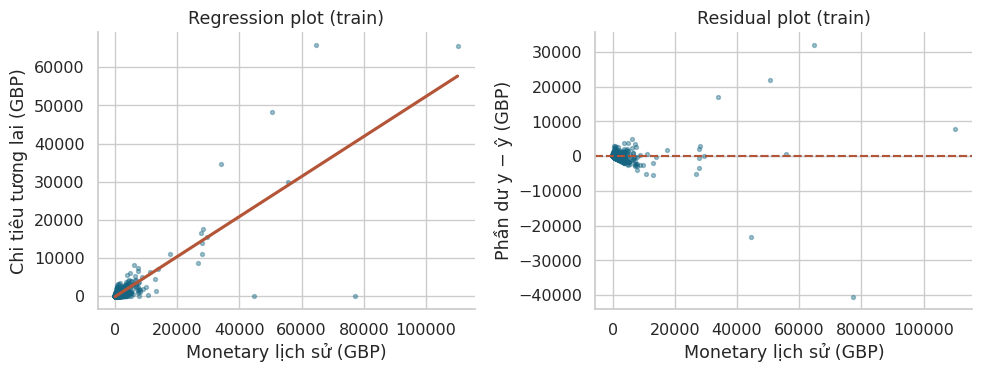

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
sns.regplot(x=X_train[SLR_FEATURE], y=y_train, ax=axes[0], ci=None,
            scatter_kws={'s': 8, 'alpha': 0.4, 'color': MAIN_COLOR}, line_kws={'color': ACCENT_COLOR})
axes[0].set(xlabel='Monetary lịch sử (GBP)', ylabel='Chi tiêu tương lai (GBP)', title='Regression plot (train)')
sns.residplot(x=X_train[SLR_FEATURE], y=y_train, ax=axes[1], scatter_kws={'s': 8, 'alpha': 0.4, 'color': MAIN_COLOR})
axes[1].axhline(0, color=ACCENT_COLOR, linestyle='--')
axes[1].set(xlabel='Monetary lịch sử (GBP)', ylabel='Phần dư y − ŷ (GBP)', title='Residual plot (train)')
save_fig(fig, '07_slr_regression_residual')

Phần dư không trải đều: gần như mọi khách tập trung ở góc trái, còn độ rộng phần dư tăng khi `Monetary` tăng (giống "trường hợp 3" ở Bài 6: phần dư tăng theo x). Nghĩa là mô hình dự đoán khách nhỏ khá sát nhưng sai rất lớn với khách mua sỉ.

## Step 16. Hồi quy tuyến tính đa biến (MLR)

Mô hình: ŷ = b0 + b1·x1 + b2·x2 + … với các biến quan trọng từ EDA. Không cần chuẩn hóa cho MLR thường (chuẩn hóa không đổi dự đoán), nên hệ số đọc được theo đơn vị gốc.

In [8]:
mlr = LinearRegression()
mlr.fit(X_train[SELECTED_FEATURES], y_train)
mlr_coef = pd.Series(mlr.coef_, index=SELECTED_FEATURES, name='coef')
terms = ' '.join(f'{b:+,.4f}*{name}' for name, b in mlr_coef.items())
print(f'{TARGET} = {mlr.intercept_:,.4f} {terms}')
mlr_coef.to_frame()

FutureSpend = 9.8980 +0.5015*Monetary +42.0312*Frequency +1.0134*Products -256.3160*IsUK


,coef
Monetary,0.5015
Frequency,42.0312
Products,1.0134
IsUK,-256.3160


Với nhiều biến, không vẽ được regression plot theo từng biến, nên dùng residual plot theo giá trị dự đoán ŷ (gợi ý "residual plot cho đa biến" ở Bài 6) và distribution plot so sánh phân phối giá trị thực tế với giá trị dự đoán.

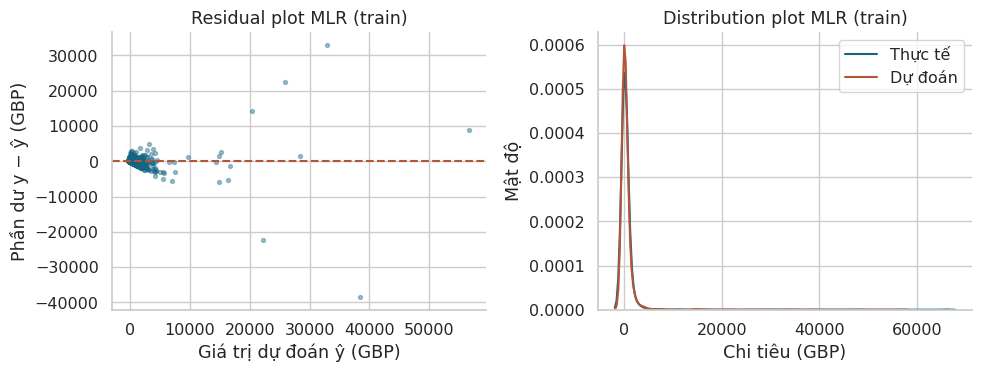

In [9]:
mlr_train_hat = mlr.predict(X_train[SELECTED_FEATURES])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))
axes[0].scatter(mlr_train_hat, y_train - mlr_train_hat, s=8, alpha=0.4, color=MAIN_COLOR)
axes[0].axhline(0, color=ACCENT_COLOR, linestyle='--')
axes[0].set(xlabel='Giá trị dự đoán ŷ (GBP)', ylabel='Phần dư y − ŷ (GBP)', title='Residual plot MLR (train)')
sns.kdeplot(y_train, ax=axes[1], label='Thực tế', color=MAIN_COLOR)
sns.kdeplot(mlr_train_hat, ax=axes[1], label='Dự đoán', color=ACCENT_COLOR)
axes[1].set(xlabel='Chi tiêu (GBP)', ylabel='Mật độ', title='Distribution plot MLR (train)')
axes[1].legend()
save_fig(fig, '08_mlr_residual_distribution')

## Step 17. Hồi quy đa thức và over/underfitting

Bài 6 giới thiệu hồi quy đa thức đơn biến bằng `np.polyfit`; dưới đây là mô hình bậc 3 theo `Monetary`. Hệ số rất nhỏ vì `Monetary` lên tới hàng chục nghìn, lũy thừa bậc 3 của nó rất lớn.

In [10]:
poly3_coef = np.polyfit(X_train[SLR_FEATURE], y_train, 3)
print(np.poly1d(poly3_coef))

           3             2
2.656e-12 x - 1.018e-10 x + 0.5089 x - 82.8


Bậc càng cao, đường hồi quy càng uốn theo dữ liệu train. Theo Bài 7, so **sai số train** với **sai số kiểm chứng chéo (CV) 5 fold** khi tăng bậc:

- Cả hai cùng cao → **underfitting** (mô hình chưa khớp).
- Train thấp nhưng CV cao → **overfitting** (mô hình quá khớp).

CV chỉ dùng tập train: mỗi fold lần lượt làm phần kiểm tra, mô hình fit trên 4 fold còn lại; `cross_val_score` trả về sai số của từng fold, CV RMSE là căn của MSE trung bình 5 fold. Đa thức nhiều bậc cần chuẩn hóa trước (khuyến nghị ở Bài 6), nên dùng Pipeline: chuẩn hóa → biến đổi đa thức → hồi quy.

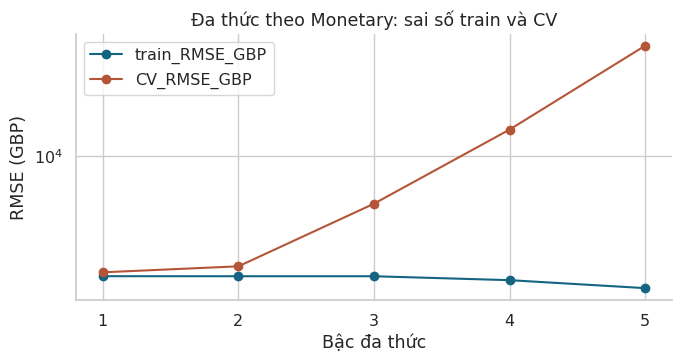

,train_RMSE_GBP,CV_RMSE_GBP
degree,,
1,"1,569.7454","1,666.3256"
2,"1,568.8291","1,827.6384"
3,"1,568.7761","4,792.8364"
4,"1,476.6063","15,003.6594"
5,"1,306.1635","54,565.3344"


In [11]:
def poly_pipeline(degree):
    """Pipeline ở Bài 6: chuẩn hóa z-score -> tạo biến đa thức -> hồi quy tuyến tính."""
    return Pipeline([('scale', StandardScaler()),
                     ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
                     ('model', LinearRegression())])

degree_rows = []
for degree in SLR_DEGREES:
    pipe = poly_pipeline(degree)
    cv_rmse = cv_scores(pipe, X_train[[SLR_FEATURE]], y_train)['CV_RMSE_GBP']
    pipe.fit(X_train[[SLR_FEATURE]], y_train)
    degree_rows.append({'degree': degree,
                        'train_RMSE_GBP': rmse(y_train, pipe.predict(X_train[[SLR_FEATURE]])),
                        'CV_RMSE_GBP': cv_rmse})
degree_curve = pd.DataFrame(degree_rows).set_index('degree')
degree_curve.to_csv(OUT_DIR / 'degree_curve.csv')

fig, ax = plt.subplots(figsize=(7, 3.8))
degree_curve.plot(ax=ax, marker='o', color=[MAIN_COLOR, ACCENT_COLOR])
ax.set(title=f'Đa thức theo {SLR_FEATURE}: sai số train và CV', xlabel='Bậc đa thức', ylabel='RMSE (GBP)')
ax.set_xticks(SLR_DEGREES)
ax.set_yscale('log')
save_fig(fig, '09_degree_overfitting')
degree_curve

Khi tăng bậc, RMSE train giảm dần (ít ở bậc 2–3, rõ ở bậc 4–5), còn RMSE CV tăng ngay từ bậc 2 và tăng vọt ở bậc cao (trục log). Đường đa thức uốn theo vài khách mua sỉ trong train rồi dự đoán rất sai cho khách ở fold khác. Đây là **overfitting**; bậc 1 (đường thẳng) vừa khớp nhất trong các bậc đã thử.

## Step 18. Pipeline đa thức đa biến

Áp dụng đúng bài tập ở Bài 6: Pipeline đa thức bậc 2 và bậc 3 cho các biến quan trọng. `PolynomialFeatures` bậc 2 biến [a, b] thành [a, b, a², ab, b²].

In [12]:
poly_example = PolynomialFeatures(degree=2, include_bias=False).fit(X_train[SELECTED_FEATURES])
print(f'{len(SELECTED_FEATURES)} biến -> bậc 2 tạo {poly_example.n_output_features_} biến:')
print(list(poly_example.get_feature_names_out()))
poly_pipeline(2)

4 biến -> bậc 2 tạo 14 biến:
['Monetary', 'Frequency', 'Products', 'IsUK', 'Monetary^2', 'Monetary Frequency', 'Monetary Products', 'Monetary IsUK', 'Frequency^2', 'Frequency Products', 'Frequency IsUK', 'Products^2', 'Products IsUK', 'IsUK^2']


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('scale', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


## Step 19. Hồi quy Ridge và Grid Search

Ridge thêm hệ số điều chỉnh **alpha** để phạt hệ số lớn: alpha = 0 là hồi quy tuyến tính thường, alpha càng lớn thì hệ số càng bị kéo về 0 và đường hồi quy càng "mềm", giảm overfitting.

`GridSearchCV` thử mọi tổ hợp bậc đa thức × alpha, chấm mỗi tổ hợp bằng CV 5 fold trên train và chọn tổ hợp có sai số thấp nhất. sklearn quy ước điểm càng lớn càng tốt nên dùng MSE âm (`neg_mean_squared_error`); bảng dưới đổi dấu rồi lấy căn để có CV RMSE.

Tham số Ridge tốt nhất (chọn trên train): {'poly__degree': 1, 'ridge__alpha': 100}


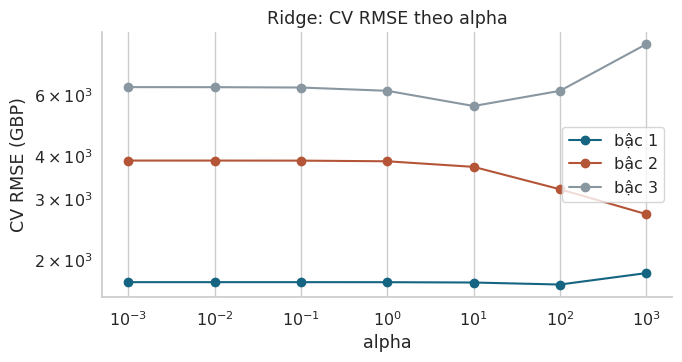

param_poly__degree,1,2,3
param_ridge__alpha,,,
0.0010,"1,724.0880","3,881.5074","6,335.9897"
0.0100,"1,724.0842","3,881.3355","6,334.4542"
0.1000,"1,724.0458","3,879.6198","6,319.2665"
1.0000,"1,723.6636","3,862.7877","6,182.5473"
10.0000,"1,720.0066","3,721.3374","5,586.0171"
100.0000,"1,696.9910","3,204.7803","6,180.9235"
"1,000.0000","1,831.5220","2,714.1628","8,440.8546"


In [13]:
ridge_pipe = Pipeline([('scale', StandardScaler()),
                       ('poly', PolynomialFeatures(include_bias=False)),
                       ('ridge', Ridge())])
ridge_grid = {'poly__degree': RIDGE_DEGREES, 'ridge__alpha': RIDGE_ALPHAS}
grid = GridSearchCV(ridge_pipe, ridge_grid, cv=CV, scoring='neg_mean_squared_error')
grid.fit(X_train[SELECTED_FEATURES], y_train)
print('Tham số Ridge tốt nhất (chọn trên train):', grid.best_params_)

cv_grid = pd.DataFrame(grid.cv_results_)
cv_grid['CV_RMSE_GBP'] = np.sqrt(-cv_grid['mean_test_score'])
ridge_table = cv_grid.pivot_table(index='param_ridge__alpha', columns='param_poly__degree', values='CV_RMSE_GBP')
ridge_table.to_csv(OUT_DIR / 'ridge_grid.csv')

fig, ax = plt.subplots(figsize=(7, 3.8))
for degree, color in zip(RIDGE_DEGREES, [MAIN_COLOR, ACCENT_COLOR, MUTED_COLOR]):
    ax.plot(ridge_table.index, ridge_table[degree], marker='o', color=color, label=f'bậc {degree}')
ax.set(xscale='log', yscale='log', xlabel='alpha', ylabel='CV RMSE (GBP)', title='Ridge: CV RMSE theo alpha')
ax.legend()
save_fig(fig, '10_ridge_alpha')
ridge_table

Bảng cho thấy cả hai phía của việc chọn alpha:

- **Bậc 2:** alpha càng lớn thì CV RMSE càng giảm, vì phạt hệ số kìm được overfitting.
- **Bậc 3:** alpha vừa phải (10) giảm sai số, nhưng alpha quá lớn lại làm sai số tăng: phạt quá mạnh khiến mô hình chưa khớp (underfitting).
- **Bậc 1:** alpha nhỏ gần như không đổi kết quả; alpha = 100 tốt nhất, alpha = 1000 bắt đầu underfitting.

Dù đã điều chỉnh, đa thức bậc 2–3 vẫn có CV RMSE cao hơn nhiều so với bậc 1. Grid Search chọn bậc 1, tức Ridge tuyến tính.

## Step 20. So sánh các mô hình bằng kiểm chứng chéo

Mọi mô hình được chấm bằng **cùng 5 fold** trên train; tập test chưa được dùng. Chọn mô hình có CV RMSE thấp nhất và **khóa** lựa chọn này trước khi mở test.

- CV RMSE là căn của MSE trung bình 5 fold; CV MAE và CV R² là trung bình 5 fold. Cả ba tính bằng `cross_val_score`.
- Cách tính CV RMSE giống hệt GridSearchCV ở Step 19, nên CV RMSE của Ridge ở hai bảng trùng nhau.

In [14]:
MODELS = {
    'Baseline (trung bình)': (SELECTED_FEATURES, DummyRegressor(strategy='mean')),
    f'SLR {SLR_FEATURE}': ([SLR_FEATURE], LinearRegression()),
    'MLR (biến EDA)': (SELECTED_FEATURES, LinearRegression()),
    'MLR (6 biến)': (FEATURES, LinearRegression()),
    'Đa thức bậc 2': (SELECTED_FEATURES, poly_pipeline(2)),
    'Đa thức bậc 3': (SELECTED_FEATURES, poly_pipeline(3)),
    'Ridge (Grid Search)': (SELECTED_FEATURES, grid.best_estimator_),
}

selection_rows = []
for name, (cols, model) in MODELS.items():
    cv_result = cv_scores(model, X_train[cols], y_train)
    model.fit(X_train[cols], y_train)
    train_hat = model.predict(X_train[cols])
    selection_rows.append({'model': name, 'n_features': len(cols),
                           'train_RMSE_GBP': rmse(y_train, train_hat), **cv_result,
                           'train_R2': r2_score(y_train, train_hat)})
selection = pd.DataFrame(selection_rows).sort_values('CV_RMSE_GBP').reset_index(drop=True)
ridge_cv = selection.set_index('model').loc['Ridge (Grid Search)', 'CV_RMSE_GBP']
assert np.isclose(ridge_cv, np.sqrt(-grid.best_score_)), 'CV RMSE của Ridge phải khớp với GridSearchCV'
selection.to_csv(OUT_DIR / 'model_selection.csv', index=False)
selection

,model,n_features,train_RMSE_GBP,CV_RMSE_GBP,CV_MAE_GBP,CV_R2_mean,train_R2
0,SLR Monetary,1,"1,569.7454","1,666.3256",394.9459,0.6672,0.6899
1,Ridge (Grid Search),4,"1,564.0153","1,696.9910",447.7228,0.6448,0.6922
2,MLR (6 biến),6,"1,551.8978","1,721.1432",436.1117,0.6465,0.6969
3,MLR (biến EDA),4,"1,559.2065","1,724.0884",443.1101,0.6401,0.6941
4,Baseline (trung bình),4,"2,818.9142","2,820.5297",689.6905,-0.0145,0.0000
5,Đa thức bậc 2,4,"1,185.8850","3,881.5265",578.1728,-0.4350,0.8230
6,Đa thức bậc 3,4,549.6031,"6,336.1605",643.1580,-3.0347,0.9620


In [15]:
# Khóa mô hình có CV RMSE thấp nhất; không đổi lựa chọn sau khi xem test
BEST_NAME = selection.loc[0, 'model']
BEST_FEATURES, best_model = MODELS[BEST_NAME]
print('Mô hình khóa trước khi đánh giá test:', BEST_NAME, '| biến:', BEST_FEATURES)

Mô hình khóa trước khi đánh giá test: SLR Monetary | biến: ['Monetary']


Trả lời các câu hỏi ở cuối Bài 6 bằng chính kết quả trên:

1. **MSE thấp hơn có luôn là mô hình tốt hơn?** Không. Trên train, mọi mô hình nhiều biến hoặc nhiều bậc đều có sai số thấp hơn SLR, vì có nhiều "tự do" hơn để khớp dữ liệu đã thấy. Nhưng trên CV (dữ liệu mô hình chưa thấy), SLR một biến lại có sai số thấp nhất.
2. **Thêm biến có luôn tốt hơn?** Không. MLR 4 biến và MLR 6 biến chỉ chênh nhau rất ít trên CV, và cả hai đều thua SLR. Phần lớn thông tin dự đoán đã nằm trong `Monetary`; các biến thêm vào còn tương quan với `Monetary` nên đóng góp thêm không đáng kể.
3. **Đa thức bậc 3** có R² train cao nhất nhưng CV R² âm: dự đoán còn tệ hơn đường trung bình, tức overfitting nặng.

Vì vậy mô hình được chọn là mô hình **đơn giản nhất nhưng tổng quát tốt nhất**, đúng tinh thần "good fitting" ở Bài 7.

# Phase 6. Đánh giá mô hình trên tập test
## Step 21. Các thang đo đánh giá

Tập test (30% khách) chỉ được mở ở bước này. Ngoài MSE và R² (Bài 6), báo cáo thêm các thang đo mà Bài 7 giao tìm hiểu:

| Thang đo | Công thức | Ý nghĩa |
| --- | --- | --- |
| RMSE | √MSE | Sai số điển hình, cùng đơn vị GBP với y |
| MAE | trung bình \|y − ŷ\| | Sai số tuyệt đối trung bình, ít bị khách cực lớn chi phối hơn RMSE |
| RSE | Σ(y − ŷ)² / Σ(y − ȳ)² | So với việc luôn đoán trung bình; RSE = 1 − R² |
| RAE | Σ\|y − ŷ\| / Σ\|y − ȳ\| | Giống RSE nhưng dùng sai số tuyệt đối |

RSE, RAE < 1 nghĩa là mô hình tốt hơn đoán trung bình của chính tập đang đánh giá. Baseline đoán trung bình của **train** nên RSE của nó nhỉnh hơn 1 một chút; RAE của baseline lại nhỏ hơn 1 vì y lệch phải, trung bình train gần trung vị hơn trung bình test, mà sai số tuyệt đối nhỏ nhất khi đoán gần trung vị. Bảng test của các mô hình khác chỉ để tham khảo, không dùng để chọn lại mô hình.

In [16]:
def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    error = y_true - y_pred
    deviation = y_true - y_true.mean()
    return {'MSE_GBP2': mean_squared_error(y_true, y_pred), 'RMSE_GBP': rmse(y_true, y_pred),
            'MAE_GBP': mean_absolute_error(y_true, y_pred), 'R2': r2_score(y_true, y_pred),
            'RSE': (error ** 2).sum() / (deviation ** 2).sum(),
            'RAE': np.abs(error).sum() / np.abs(deviation).sum(),
            'negative_predictions': int((y_pred < 0).sum())}

test_metrics = pd.DataFrame([{'model': name, **metrics(y_test, model.predict(X_test[cols]))}
                             for name, (cols, model) in MODELS.items()])
assert np.allclose(test_metrics['RSE'], 1 - test_metrics['R2'])
test_metrics.to_csv(OUT_DIR / 'test_metrics.csv', index=False)
test_metrics

,model,MSE_GBP2,RMSE_GBP,MAE_GBP,R2,RSE,RAE,negative_predictions
0,Baseline (trung bình),"6,521,903.3836","2,553.8018",779.3521,-0.0027,1.0027,0.9178,0
1,SLR Monetary,"3,442,366.8759","1,855.3617",492.9188,0.4707,0.5293,0.5805,146
2,MLR (biến EDA),"3,497,828.2632","1,870.2482",532.4892,0.4622,0.5378,0.6271,284
3,MLR (6 biến),"3,558,747.2664","1,886.4642",529.4930,0.4529,0.5471,0.6235,190
4,Đa thức bậc 2,"4,691,129.8176","2,165.9016",608.3039,0.2788,0.7212,0.7163,50
5,Đa thức bậc 3,"13,009,269.1628","3,606.8364",701.2751,-1.0001,2.0001,0.8258,14
6,Ridge (Grid Search),"3,555,373.4742","1,885.5698",537.1628,0.4534,0.5466,0.6326,276


In [17]:
y_hat = best_model.predict(X_test[BEST_FEATURES])
predictions = pd.DataFrame({'CustomerID': X_test.index, 'actual_GBP': y_test.values, 'predicted_GBP': y_hat})
predictions['residual_GBP'] = predictions['actual_GBP'] - predictions['predicted_GBP']
predictions['absolute_error_GBP'] = predictions['residual_GBP'].abs()
predictions.to_csv(OUT_DIR / 'test_predictions.csv', index=False)

test_by_model = test_metrics.set_index('model')
baseline_rmse = test_by_model.loc['Baseline (trung bình)', 'RMSE_GBP']
best_rmse = test_by_model.loc[BEST_NAME, 'RMSE_GBP']
rmse_gain = 100 * (1 - best_rmse / baseline_rmse)
print(f'{BEST_NAME}: test RMSE {best_rmse:,.2f} GBP, giảm {rmse_gain:.2f}% so với baseline trung bình')
print(f"CV RMSE trên train: {selection.loc[0, 'CV_RMSE_GBP']:,.2f} GBP")

SLR Monetary: test RMSE 1,855.36 GBP, giảm 27.35% so với baseline trung bình
CV RMSE trên train: 1,666.33 GBP


Trên test, SLR vẫn có RMSE, MAE và RAE thấp nhất; ba mô hình tuyến tính nhiều biến bám sát phía sau, còn đa thức bậc 3 kém nhất, giống kết luận từ CV. Vậy lựa chọn bằng CV đứng vững khi gặp khách mới. R² test thấp hơn CV R² vì tập test có vài khách mua sỉ mà mô hình đoán sai rất xa (Step 23). Vì R² bị vài khách này kéo xuống, nên đọc kèm MAE và RAE.

## Step 22. Đánh giá bằng trực quan

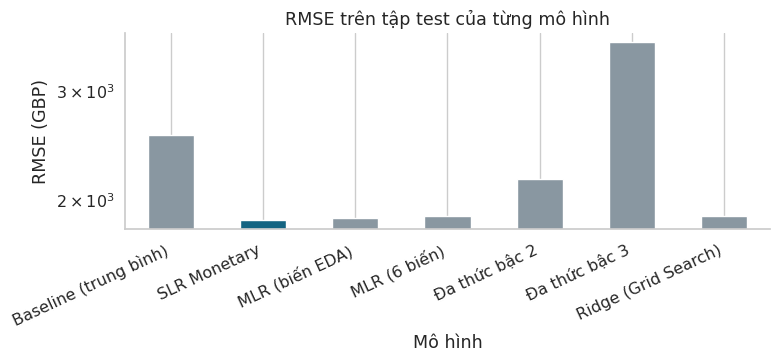

In [18]:
test_rmse = test_by_model['RMSE_GBP']
bar_colors = [MAIN_COLOR if name == BEST_NAME else MUTED_COLOR for name in test_rmse.index]
fig, ax = plt.subplots(figsize=(8, 3.8))
test_rmse.plot.bar(ax=ax, color=bar_colors)
ax.set(title='RMSE trên tập test của từng mô hình', xlabel='Mô hình', ylabel='RMSE (GBP)', yscale='log')
plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
save_fig(fig, '11_model_comparison')

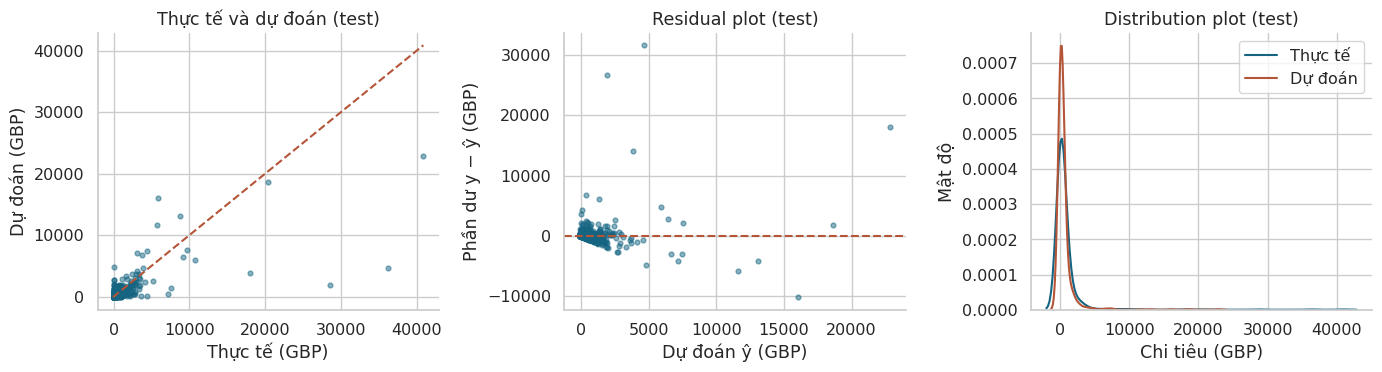

In [19]:
lo = min(0, float(y_hat.min()))
hi = max(float(y_test.max()), float(y_hat.max()))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))
axes[0].scatter(y_test, y_hat, s=12, alpha=0.5, color=MAIN_COLOR)
axes[0].plot([lo, hi], [lo, hi], '--', color=ACCENT_COLOR)
axes[0].set(xlabel='Thực tế (GBP)', ylabel='Dự đoán (GBP)', title='Thực tế và dự đoán (test)')
axes[1].scatter(y_hat, y_test.values - y_hat, s=12, alpha=0.5, color=MAIN_COLOR)
axes[1].axhline(0, color=ACCENT_COLOR, linestyle='--')
axes[1].set(xlabel='Dự đoán ŷ (GBP)', ylabel='Phần dư y − ŷ (GBP)', title='Residual plot (test)')
sns.kdeplot(y_test, ax=axes[2], label='Thực tế', color=MAIN_COLOR)
sns.kdeplot(y_hat, ax=axes[2], label='Dự đoán', color=ACCENT_COLOR)
axes[2].set(xlabel='Chi tiêu (GBP)', ylabel='Mật độ', title='Distribution plot (test)')
axes[2].legend()
save_fig(fig, '12_test_diagnostics')

Các điểm gần đường chéo là dự đoán đúng. Phần lớn khách nằm sát góc trái dưới, còn vài khách mua sỉ nằm xa đường chéo và quyết định gần hết RMSE. Trên distribution plot, đường KDE làm trơn nên phần đuôi trái kéo xuống dưới 0 dù y không âm; đỉnh tại 0 là thật vì khoảng một nửa khách test có y = 0.

## Step 23. Dự đoán có hợp lý không?

Bài 6 (mục 8) nhắc phải kiểm tra giá trị dự đoán có hợp lý không. Chi tiêu không thể âm, nên đếm số dự đoán âm và tìm ngưỡng `Monetary` mà SLR bắt đầu dự đoán âm (ŷ = 0 khi x = −b0/b1).

In [20]:
if b0 < 0:
    zero_point = -b0 / b1
    below = (X_test[SLR_FEATURE] < zero_point).mean()
    print(f'SLR dự đoán âm khi {SLR_FEATURE} < {zero_point:,.2f} GBP ({below:.1%} khách test)')

# Dự đoán trên một dãy giá trị Monetary (np.arange như Bài 6) để thấy đường dự đoán
monetary_grid = pd.DataFrame({SLR_FEATURE: np.arange(0, 3001, 500)})
monetary_grid['SLR_prediction_GBP'] = slr.predict(monetary_grid[[SLR_FEATURE]])
monetary_grid

SLR dự đoán âm khi Monetary < 186.57 GBP (17.9% khách test)


,Monetary,SLR_prediction_GBP
0,0,-97.8529
1,500,164.3953
2,1000,426.6435
3,1500,688.8917
4,2000,951.1399
5,2500,"1,213.3882"
6,3000,"1,475.6364"


In [21]:
# Chặn dự đoán âm tại 0 là bước hậu xử lý đơn giản; báo cáo riêng, bảng chính giữ dự đoán gốc
clipped_metrics = metrics(y_test, np.maximum(0, y_hat))
pd.DataFrame({'dự đoán gốc': metrics(y_test, y_hat), 'chặn tại 0': clipped_metrics})

,dự đoán gốc,chặn tại 0
MSE_GBP2,"3,442,366.8759","3,441,427.8588"
RMSE_GBP,"1,855.3617","1,855.1086"
MAE_GBP,492.9188,486.9770
R2,0.4707,0.4709
RSE,0.5293,0.5291
RAE,0.5805,0.5735
negative_predictions,146.0000,0.0000


In [22]:
# Sai số lớn nhất: không loại khỏi test
error_sorted = predictions.sort_values('absolute_error_GBP', ascending=False)
top5_sse_share = (error_sorted.head(5)['residual_GBP'].pow(2).sum()
                  / predictions['residual_GBP'].pow(2).sum())
print(f'Năm sai số lớn nhất chiếm {top5_sse_share:.2%} tổng bình phương sai số (SSE)')
error_sorted.head(5)

Năm sai số lớn nhất chiếm 83.31% tổng bình phương sai số (SSE)


,CustomerID,actual_GBP,predicted_GBP,residual_GBP,absolute_error_GBP
756,17949,"36,266.8000","4,653.4554","31,613.3446","31,613.3446"
62,12931,"28,610.0000","1,958.5403","26,651.4597","26,651.4597"
476,14156,"40,885.1200","22,844.7911","18,040.3289","18,040.3289"
619,14088,"17,962.9800","3,859.4255","14,103.5545","14,103.5545"
671,15061,"5,852.0800","16,016.2093","-10,164.1293","10,164.1293"


In [23]:
# Sai số theo nhóm Recency (gom nhóm như Bài 5)
error_by_recency = (predictions.set_index('CustomerID')
                    .join(customers['RecencyGroup'])
                    .groupby('RecencyGroup', sort=False)
                    .agg(n=('actual_GBP', 'size'), mean_actual=('actual_GBP', 'mean'),
                         mean_predicted=('predicted_GBP', 'mean'), MAE=('absolute_error_GBP', 'mean')))
error_by_recency

,n,mean_actual,mean_predicted,MAE
RecencyGroup,,,,
≤30 ngày,312,"1,237.2336","1,034.6137",784.0599
31–90 ngày,283,315.6675,274.0458,277.8644
>90 ngày,220,308.2145,152.6018,356.6658


# Phase 7. Diễn giải và mở rộng
## Step 24. Fit lại trên toàn bộ dữ liệu

Bài 7: sau khi đánh giá xong, nên dùng lại **tất cả dữ liệu** (train + test) để fit lại mô hình đã chọn, vì nhiều dữ liệu hơn cho hệ số ổn định hơn. Cấu hình mô hình giữ nguyên, chỉ học lại hệ số; `clone` tạo bản sao chưa fit của mô hình đã khóa.

In [24]:
final_model = clone(best_model)
final_model.fit(X[BEST_FEATURES], y)
if isinstance(final_model, LinearRegression):
    final_terms = ' '.join(f'{b:+.6f}*{name}' for name, b in zip(BEST_FEATURES, final_model.coef_))
    print(f'Mô hình cuối: {TARGET} = {final_model.intercept_:,.4f} {final_terms}')

Mô hình cuối: FutureSpend = -71.9614 +0.536406*Monetary


## Step 25. Kiểm tra trên quý kế tiếp (phần làm thêm)

Phép chia train/test ngẫu nhiên chỉ cho biết mô hình dự đoán tốt cho **khách khác trong cùng quý**. Khi dùng thật, doanh nghiệp fit mô hình hôm nay để dự đoán quý **sau**. Để kiểm tra điều đó, dùng mô hình cuối ở Step 24 (chỉ học từ dữ liệu trước 01/09/2011) dự đoán cho quý 01/09–30/11/2011:

- X tính từ lịch sử 6 tháng 01/03–31/08/2011, cùng độ dài lịch sử với kỳ chính.
- Toàn bộ dữ liệu quý này chưa từng được dùng khi làm EDA, chọn biến hay chọn mô hình.
- Baseline vẫn là trung bình y của kỳ chính, vì tại thời điểm dự đoán chưa biết y của quý sau.

Quý 9–11 có mùa mua sắm cuối năm, nên khách chi nhiều hơn hẳn. Nếu mô hình vẫn thắng baseline rõ ràng thì kết luận "lịch sử chi tiêu dự đoán được chi tiêu quý sau" đáng tin hơn.

In [25]:
customers_next = pd.read_csv(OUT_DIR / 'customers_next_quarter.csv',
                             index_col='CustomerID', dtype={'CustomerID': 'string'})
y_next = customers_next[TARGET]
next_hat = final_model.predict(customers_next[BEST_FEATURES])
next_baseline = np.full(len(y_next), y.mean())

next_quarter = pd.DataFrame({'baseline (trung bình kỳ chính)': metrics(y_next, next_baseline),
                             f'{BEST_NAME} (mô hình cuối)': metrics(y_next, next_hat)})
next_gain = 100 * (1 - rmse(y_next, next_hat) / rmse(y_next, next_baseline))
next_quarter.to_csv(OUT_DIR / 'next_quarter_metrics.csv', encoding='utf-8-sig')
print(f'Quý kế tiếp: {len(y_next):,} khách | y trung bình {y_next.mean():,.2f} GBP (kỳ chính {y.mean():,.2f} GBP)')
print(f'Giảm RMSE so với baseline: {next_gain:.2f}%')
next_quarter

Quý kế tiếp: 2,809 khách | y trung bình 867.36 GBP (kỳ chính 573.27 GBP)
Giảm RMSE so với baseline: 39.19%


,baseline (trung bình kỳ chính),SLR Monetary (mô hình cuối)
MSE_GBP2,"17,631,940.7498","6,519,748.6510"
RMSE_GBP,"4,199.0405","2,553.3798"
MAE_GBP,900.9113,583.7169
R2,-0.0049,0.6284
RSE,1.0049,0.3716
RAE,0.8702,0.5638
negative_predictions,0.0000,278.0000


In [26]:
# So sánh tổng chi tiêu dự đoán và thực tế của cả quý: mô hình có đoán thấp hay cao có hệ thống không
pd.Series({'Tổng thực tế (GBP)': y_next.sum(), 'Tổng dự đoán (GBP)': next_hat.sum(),
           'Tỷ lệ dự đoán / thực tế': next_hat.sum() / y_next.sum()}, name='value').to_frame()

,value
Tổng thực tế (GBP),"2,436,419.3700"
Tổng dự đoán (GBP),"1,716,698.7323"
Tỷ lệ dự đoán / thực tế,0.7046


- Trên quý mô hình chưa từng thấy, mô hình vẫn giảm RMSE rõ rệt so với baseline và R² còn cao hơn trên tập test. Vậy lịch sử chi tiêu dự đoán được chi tiêu của quý sau, không chỉ đúng với khách khác trong cùng quý.
- Tổng dự đoán chỉ bằng khoảng 70% tổng thực tế: mô hình học từ quý hè nên **đoán thấp có hệ thống** trong mùa mua sắm cuối năm. Mô hình vẫn phân biệt được khách chi nhiều và chi ít (R² dương rõ), nhưng mức tuyệt đối cần điều chỉnh theo mùa nếu dùng để lập kế hoạch doanh thu.

## Step 26. Kiểm tra độ nhạy: giữ dòng trùng

Dùng bảng khách tạo từ dữ liệu **không** loại dòng trùng (notebook analysis đã lưu). Giữ cùng mã khách, cùng phép chia và cùng cấu hình mô hình đã khóa; không chọn lại mô hình. Nếu chỉ số gần như không đổi thì quyết định loại dòng trùng không ảnh hưởng kết luận.

In [27]:
customers_keep_dup = pd.read_csv(OUT_DIR / 'customers_keep_duplicates.csv',
                                 index_col='CustomerID', dtype={'CustomerID': 'string'})
assert set(customers_keep_dup.index) == set(customers.index)

sensitivity_model = clone(best_model)
sensitivity_model.fit(customers_keep_dup.loc[X_train.index, BEST_FEATURES],
                      customers_keep_dup.loc[X_train.index, TARGET])
sensitivity_hat = sensitivity_model.predict(customers_keep_dup.loc[X_test.index, BEST_FEATURES])
sensitivity_metrics = metrics(customers_keep_dup.loc[X_test.index, TARGET], sensitivity_hat)
pd.DataFrame({'loại dòng trùng': metrics(y_test, y_hat), 'giữ dòng trùng': sensitivity_metrics})

,loại dòng trùng,giữ dòng trùng
MSE_GBP2,"3,442,366.8759","3,444,248.4430"
RMSE_GBP,"1,855.3617","1,855.8686"
MAE_GBP,492.9188,493.9357
R2,0.4707,0.4709
RSE,0.5293,0.5291
RAE,0.5805,0.5806
negative_predictions,146.0000,145.0000


Các chỉ số gần như không đổi khi giữ dòng trùng, nên quyết định loại dòng trùng ở Phase 2 không ảnh hưởng đến kết luận.

## Step 27. Demo trên khách test

Ba khách test đại diện: một khách không mua (y = 0), một khách gần trung vị chi tiêu dương và một khách gần phân vị 90% chi tiêu dương. Demo dùng mô hình fit trên train (khách test chưa được thấy) và gồm cả trường hợp dự đoán sai.

In [28]:
zero_id = y_test.loc[y_test.eq(0)].index[0]
positive = y_test.loc[y_test.gt(0)]
median_id = (positive - positive.median()).abs().idxmin()
high_id = (positive - positive.quantile(0.90)).abs().idxmin()
demo_ids = list(dict.fromkeys([zero_id, median_id, high_id]))

demo = predictions.set_index('CustomerID').loc[demo_ids].join(X_test[FEATURES])
demo.to_csv(OUT_DIR / 'demo_customers.csv', encoding='utf-8-sig')
demo.round(2)

,actual_GBP,predicted_GBP,residual_GBP,absolute_error_GBP,Monetary,Frequency,Recency,Tenure,Products,IsUK
CustomerID,,,,,,,,,,
15674,0.0000,450.2200,-450.2200,450.2200,"1,044.9500",3,23.3300,62.6100,38,1
12569,574.7000,342.8900,231.8100,231.8100,840.3200,5,26.6100,60.4300,28,0
13078,"2,449.9900","2,245.1600",204.8300,204.8300,"4,467.1600",10,8.4900,174.6200,67,1


## Tổng hợp kết quả

In [29]:
summary = {**analysis_summary,
           'selected_model': BEST_NAME, 'selected_model_features': BEST_FEATURES,
           'ridge_params': grid.best_params_,
           'slr_intercept': float(b0), 'slr_coef': float(b1),
           'mlr_intercept': float(mlr.intercept_), 'mlr_coefficients': {k: float(v) for k, v in mlr_coef.items()},
           'test_metrics': metrics(y_test, y_hat), 'test_clipped_metrics': clipped_metrics,
           'rmse_gain_over_mean_pct': float(rmse_gain), 'top5_sse_share_pct': float(top5_sse_share * 100),
           'next_quarter_metrics': metrics(y_next, next_hat), 'next_quarter_rmse_gain_pct': float(next_gain),
           'sensitivity_keep_duplicates': sensitivity_metrics}
(OUT_DIR / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')

final_row = test_by_model.loc[BEST_NAME]
pd.Series({'Mô hình': BEST_NAME,
           'CV RMSE (GBP)': f"{selection.loc[0, 'CV_RMSE_GBP']:,.2f}",
           'Test RMSE (GBP)': f"{final_row['RMSE_GBP']:,.2f}",
           'Test MAE (GBP)': f"{final_row['MAE_GBP']:,.2f}",
           'Test R²': f"{final_row['R2']:.4f}",
           'Giảm RMSE so với baseline (test)': f'{rmse_gain:.2f}%',
           'Giảm RMSE so với baseline (quý kế tiếp)': f'{next_gain:.2f}%',
           'Dự đoán âm (test)': f"{int(final_row['negative_predictions'])} / {len(y_test)}"},
          name='value').to_frame()

,value
Mô hình,SLR Monetary
CV RMSE (GBP),"1,666.33"
Test RMSE (GBP),"1,855.36"
Test MAE (GBP),492.92
Test R²,0.4707
Giảm RMSE so với baseline (test),27.35%
Giảm RMSE so với baseline (quý kế tiếp),39.19%
Dự đoán âm (test),146 / 815


**Giới hạn:**

- Chỉ xét khách đã định danh (có `CustomerID`) và chi tiêu mua hàng dương.
- Mô hình tuyến tính dự đoán âm cho khách có lịch sử nhỏ và không tách được hai câu hỏi "có mua không" và "mua bao nhiêu".
- RMSE phụ thuộc mạnh vào vài khách mua sỉ.
- Mới kiểm tra trên một quý kế tiếp.